# Hiểu dữ liệu UCI Appliances
Dữ liệu thật của một ngôi nhà. Mục tiêu là điện năng Appliances, đơn vị nguồn Wh, đổi sang kWh. Phân tích định hướng đặc trưng chỉ sử dụng TRAIN.

In [1]:
from pathlib import Path
import sys,json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/appliances').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image
from src.appliances.config import RELEASE,MODEL_DIR,HORIZONS,BOUNDARIES
from src.appliances.data import load_data
from src.appliances.features import supervised,split_rows,make_features,feature_columns
raw,audit=load_data()
rows,columns=supervised(raw)
parts,counts=split_rows(rows)
def read_json(name):
    return json.loads((RELEASE/name).read_text(encoding='utf-8'))


In [2]:
display(pd.Series(audit, name="audit"))
train_raw=raw[raw.timestamp<pd.Timestamp(BOUNDARIES[1])]
display(train_raw[["energy_kWh","T1","RH_1"]].describe())

source_url              https://archive.ics.uci.edu/static/public/374/...
sha256                  2820bf712ad0275cb18b85a05250926100d8e65ebb9f4d...
rows                                                                19735
columns                                                                29
start                                                 2016-01-11 17:00:00
end                                                   2016-05-27 18:00:00
missing_cells                                                           0
duplicates                                                              0
frequency_minutes                                                      10
zero_energy_rows                                                        0
negative_energy_rows                                                    0
unit_conversion                         energy_kWh = Appliances_Wh / 1000
timestamp_assumption    Declared timestamp orders completed measuremen...
weather_excluded        Airport series

,energy_kWh,T1,RH_1
count,13002.000000,13002.000000,13002.000000
mean,0.098542,20.996486,40.294937
std,0.107037,1.239404,3.604516
min,0.010000,16.790000,31.426667
25%,0.050000,20.200000,37.566667
50%,0.060000,21.100000,39.900000
75%,0.100000,21.856667,43.160000
max,1.080000,24.100000,63.360000


## Nguồn đo và phân tích 3B
Điện năng được ghi bằng M-Bus, cảm biến nhiệt độ/độ ẩm bằng ZigBee. Broken được kiểm bằng missing, duplicate và lưới 10 phút. Bad Quality gồm độ phân giải, đỉnh và độ chính xác cảm biến chưa được chứng nhận độc lập. Background thiếu lịch thiết bị, người dùng và dữ liệu can thiệp.

Nguồn https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction

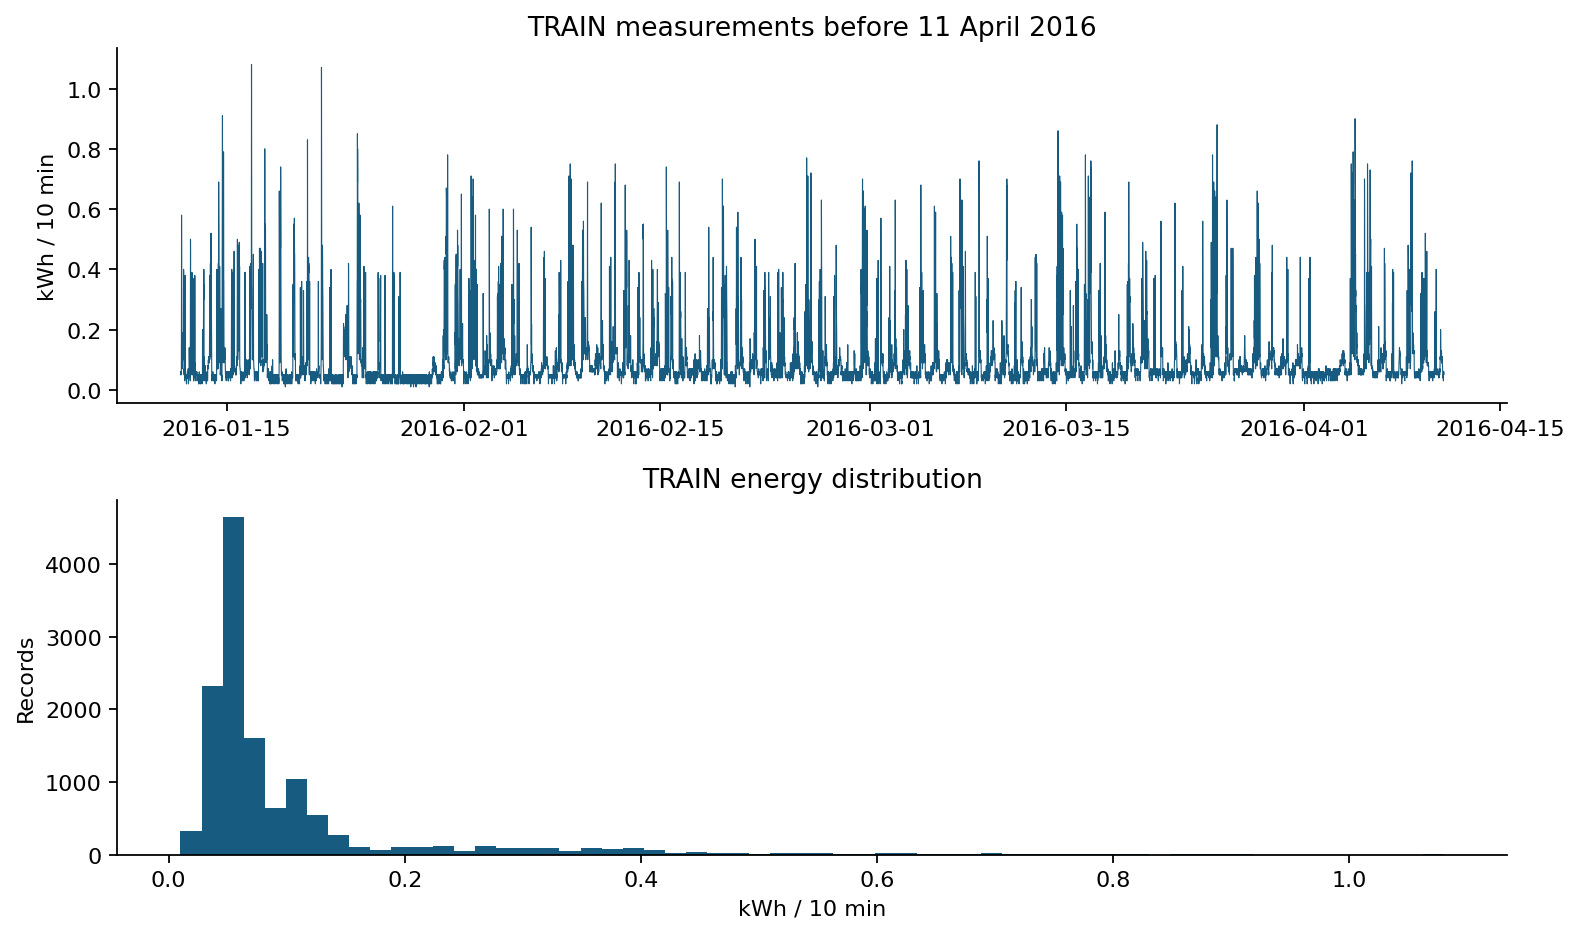

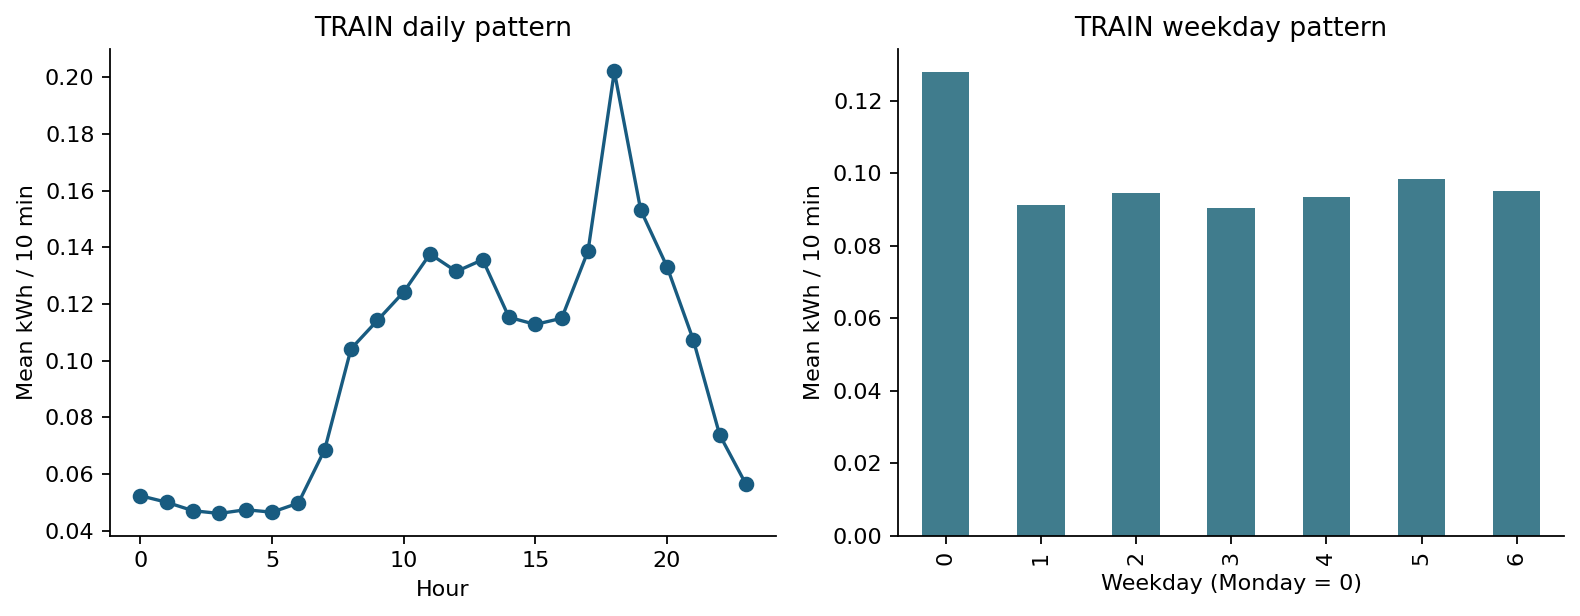

In [3]:
display(Image(filename=str(RELEASE/"figures/01_train_data.png")))
display(Image(filename=str(RELEASE/"figures/02_calendar.png")))

## Vì sao giữ đỉnh
Giá trị cao có thể là hoạt động thiết bị thật. Cắt theo IQR mà chưa hiểu nguyên nhân có thể xóa chính những trường hợp cần cảnh báo.

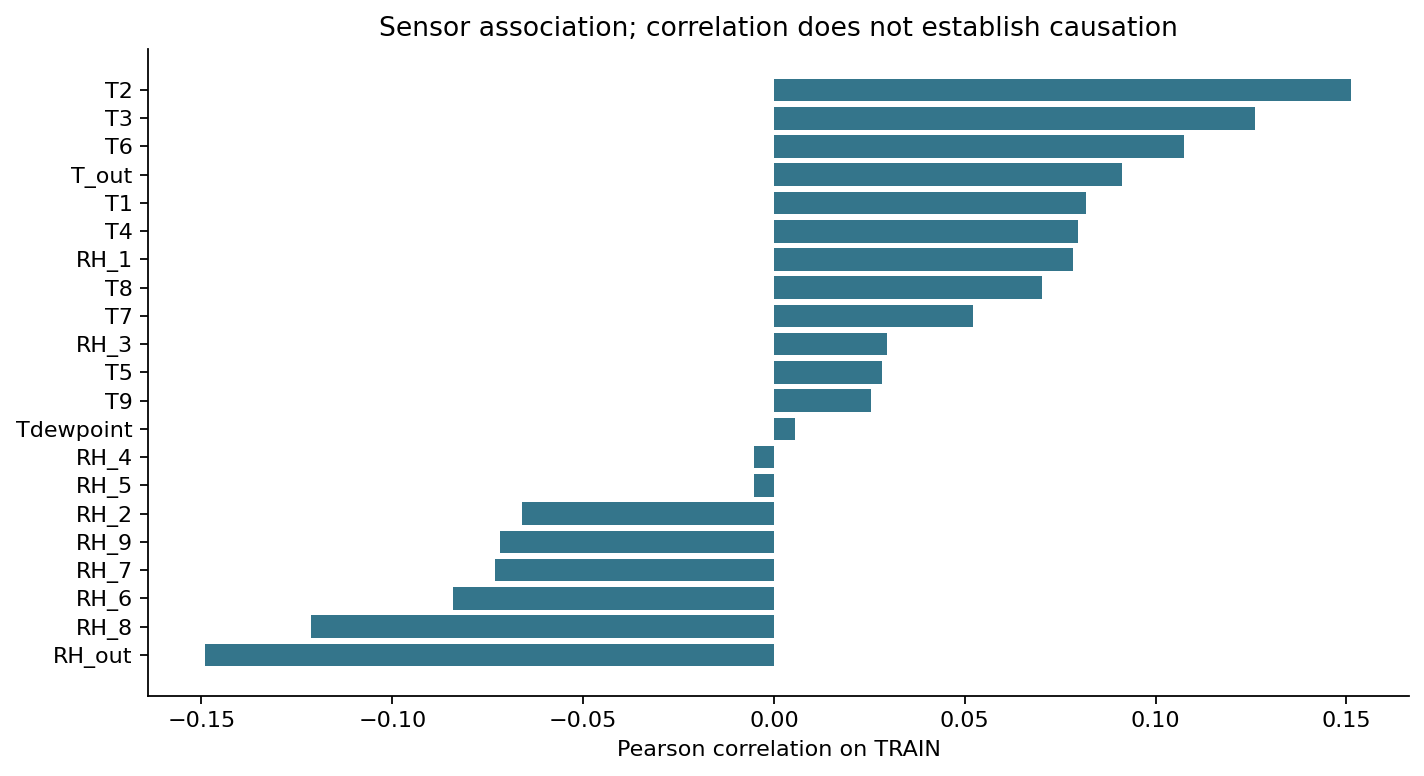

Weather upstream interpolation excluded from production features; rv1/rv2 excluded.


In [4]:
display(Image(filename=str(RELEASE/"figures/10_sensors.png")))
print("Weather upstream interpolation excluded from production features; rv1/rv2 excluded.")